# 🎓 Kompleksowy Benchmark Modeli Predykcji Rynku Bitcoin
## Analiza Porównawcza: XGBoost, SVM, SARIMAX, LSTM, BLSTM oraz Temporal Fusion Transformer (TFT)

**Autor pracy:** Adam Detmer / Bartłomiej Komoń  
**Kierunek / Temat:** Zastosowanie metod uczenia maszynowego i głębokiego w prognozowaniu szeregów czasowych kryptowalut  
**Data wykonania eksperymentów:** Marzec 2026  

---

### 📌 Streszczenie i Cel Badania
Celem niniejszego notebooka jest przeprowadzenie rygorystycznej, empirycznej ewaluacji 6 rodzin modeli w zadaniu przewidywania krótkoterminowych, dynamicznych impulsów wzrostowych ceny Bitcoina (BTC/USDT):
1. **Ekonomiczne sformułowanie problemu:** Zamiast klasycznego pytania *"czy cena za 24h będzie wyższa niż teraz"* (które jest podatne na losowy szum i nie tworzy przewagi handlowej), modelujemy prawdopodobieństwo zdarzenia **Touch +1.5% w ciągu 24h** (`target_touch_up`).
2. **Koszty transakcyjne:** Każda symulowana transakcja uwzględnia realną prowizję giełdową giełd kryptowalutowych (Binance/Bybit VIP0) na poziomie **0.05% prowizji taker na wejściu i 0.05% na wyjściu** (łącznie **0.10% round-trip**).
3. **Symulacja portfelowa:** Weryfikujemy zachowanie portfela startującego z kapitałem początkowym **$10,000 USD** na niewidzianym zbiorze testowym out-of-sample (maj 2025 – marzec 2026).
4. **Trwałość modeli:** Wytrenowane modele czempionów zostały zserializowane na dysku w katalogu `models/benchmarks/` i można je w dowolnym momencie wczytać bez konieczności czasochłonnego ponownego trenowania.

In [1]:
# Import niezbędnych bibliotek do analizy i wizualizacji
import os
import sys
import json
import glob
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Ustawienia estetyki wykresów w stylu publikacji naukowej
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

# Ustalenie ścieżek projektowych
CURRENT_DIR = os.path.abspath(os.getcwd())
# Szukamy katalogu głównego projektu
candidate_roots = [
    CURRENT_DIR,
    os.path.abspath(os.path.join(CURRENT_DIR, '..')),
    os.path.abspath(os.path.join(CURRENT_DIR, '..', '..'))
]
ROOT_DIR = None
for c in candidate_roots:
    if os.path.exists(os.path.join(c, 'data')) and os.path.exists(os.path.join(c, 'models')):
        ROOT_DIR = c
        break
if ROOT_DIR is None:
    ROOT_DIR = CURRENT_DIR

MODELS_DIR = os.path.join(ROOT_DIR, 'models', 'benchmarks')
REPORTS_DIR = os.path.join(ROOT_DIR, 'reports', 'benchmarks')
DATA_PATH = os.path.join(ROOT_DIR, 'data', 'hourly', 'processed', 'bitcoin_hourly_final.csv')

print(f"Katalog główny repozytorium: {ROOT_DIR}")
print(f"Katalog modeli:             {MODELS_DIR}")
print(f"Katalog raportów:            {REPORTS_DIR}")

Katalog główny repozytorium: c:\Users\bartl\OneDrive\Pulpit\magisterka
Katalog modeli:             c:\Users\bartl\OneDrive\Pulpit\magisterka\models\benchmarks
Katalog raportów:            c:\Users\bartl\OneDrive\Pulpit\magisterka\reports\benchmarks


---
## 1. Opis Zbioru Danych, Inżynieria Cech i Cel Predykcyjny

### 📊 Charakterystyka Zbioru Danych
Zbiór danych obejmuje **godzinowe świece Bitcoina (BTC/USDT)** z lat **2018–2026** (ponad 72 000 obserwacji).

Zbiór został podzielony ściśle chronologicznie (**Time-Series Split**) z zachowaniem buforów zapobiegających wyciekowi danych (*data leakage*):
- **Zbiór treningowy (80%):** 2018-01-01 do ~2024-07-15 (~58 000 godzin).
- **Zbiór walidacyjny (10%):** ~2024-07-15 do ~2025-05-10 (~7 250 godzin) – służący do wczesnego zatrzymania uczenia (*early stopping*) oraz kalibracji progu decyzyjnego $\tau$.
- **Zbiór testowy out-of-sample (10%):** ~2025-05-10 do ~2026-03-31 (~7 250 godzin) – całkowicie odcięty zbiór ślepej próby symulujący realny trading.

### 🔬 Grupy Cech (Feature Engineering)
W procesie inżynierii cech przygotowano 36 wskaźników podzielonych na 4 kluczowe filary:
1. **Dynamika Cenowa i Wolumen (Price Action & Flow):** Logarytmiczne stopy zwrotu (1h, 4h, 12h, 24h), znormalizowany wolumen, log-range $\ln(High/Low)$.
2. **Klasyczna Analiza Techniczna (TA):** RSI (14h, 24h), wstęgi Bollingera (%B, szerokość wstęgi), ATR, MACD histogram, Stochastic Oscillator.
3. **Mikrostruktura i Rynki Derywatów (Derivatives & Options):**
   - **Funding Rate** (stopa finansowania kontraktów perpetual na Binance/Bybit).
   - **Open Interest Delta** (napływ/odpływ kapitału lewarowanego).
   - **DVOL** (Deribit Bitcoin Implied Volatility Index – 30-dniowa implikowana zmienność z rynku opcji).
   - **25-Delta Skew** (asymetria cen opcji Put vs Call – miernik rynkowego strachu i popytu na ubezpieczenie przed spadkami).
4. **Cykliczność Czasowa:** Sinus i cosinus godziny doby (0-23h) oraz dnia tygodnia (0-6).

### 🎯 Definicja Celu: `target_touch_up` (+1.5% w 24h)
Zamiast przewidywać sam znak świecy w punkcie $t+24$, definiujemy cel jako:
$$y_t = \mathbb{I}\left( \max_{1 \le k \le 24} \frac{High_{t+k} - Close_t}{Close_t} \ge 0.015 \right)$$
Oznacza to, że model generuje sygnał kupna, jeżeli w ciągu kolejnych 24 godzin pojawi się szansa na zamknięcie zysku z poziomu Take-Profit wynoszącego $+1.5\%$. Udział klasy pozytywnej w całym zbiorze wynosi ok. **40.6%** (klasa lekko niezbalansowana).

In [2]:
# Weryfikacja integralności zbioru danych i rozkładu klas
if os.path.exists(DATA_PATH):
    df_sample = pd.read_csv(DATA_PATH, nrows=5000)
    print(f"Plik danych istnieje: {DATA_PATH}")
    print(f"Dostępne kolumny ({len(df_sample.columns)}): {list(df_sample.columns[:10])} ...")
    
    # Obliczenie targetu target_touch_up (+1.5% w 24h)
    rolling_high = df_sample['High'].iloc[::-1].rolling(24, min_periods=1).max().iloc[::-1]
    df_sample['target_touch_up'] = ((rolling_high - df_sample['Close']) / df_sample['Close'] >= 0.015).astype(int)
    
    target_counts = df_sample['target_touch_up'].value_counts()
    print(f"\nRozkład target_touch_up (+1.5% w oknie 24h) w próbce danych:")
    print(f" - Brak dotknięcia +1.5% (0): {target_counts.get(0, 0)} ({target_counts.get(0, 0)/len(df_sample)*100:.1f}%)")
    print(f" - Dotknięcie +1.5% (1):      {target_counts.get(1, 0)} ({target_counts.get(1, 0)/len(df_sample)*100:.1f}%)")
else:
    print(f"Nie znaleziono pliku pod ścieżką {DATA_PATH}. Używamy danych z raportów JSON.")

Plik danych istnieje: c:\Users\bartl\OneDrive\Pulpit\magisterka\data\hourly\processed\bitcoin_hourly_final.csv
Dostępne kolumny (47): ['Volume USDT', 'Volume BTC', 'tradecount', 'Open', 'High', 'Low', 'Close', 'timestamp', 'dvol_close', 'btc_price'] ...

Rozkład target_touch_up (+1.5% w oknie 24h) w próbce danych:
 - Brak dotknięcia +1.5% (0): 2152 (43.0%)
 - Dotknięcie +1.5% (1):      2848 (57.0%)


---
## 2. Metodologia Ewaluacji i Model Prowizji Giełdowych

W finansowym uczeniu maszynowym standardowe podejście akademickie często cierpi na brak realizmu. W naszej pracy przyjęliśmy ścisły aparat ewaluacyjny:

### 1. Dlaczego samo Accuracy jest zwodnicze?
Gdyby model zawsze przewidywał klasę większościową (0 – brak wzrostu), osiągnąłby dokładność rzędu **59.4%**, generując **0 transakcji i 0 zysku**. Z tego powodu bazujemy na:
- **ROC-AUC (Area Under ROC Curve):** Mierzy zdolność modelu do właściwego rangowania prawdopodobieństw niezależnie od przyjętego progu decyzyjnego.
- **Precision (Precyzja / Win Rate):** $\frac{TP}{TP + FP}$. W tradingu jest to odsetek zyskownych wejść na wybranym progu decyzyjnym $\tau$. Jeśli Precision wynosi $80\%$, to 8 na 10 pozycji kończy się sukcesem.

### 2. Kalibracja Progu Decyzyjnego $\tau$
Większość modeli domyślnie klasyfikuje przy progu $\tau = 0.50$. Na rynkach finansowych optymalny próg wejścia w pozycję jest przesunięty w prawo (np. $\tau \in [0.60, 0.72]$). Wchodzimy na rynek tylko wtedy, gdy model jest **wysoce pewny** swego sygnału, filtrując fałszywe wybicia (*whipsaws*).

### 3. Model Wykonania Zleceń i Prowizji (Taker Fee 0.05%)
- Każde otwarcie pozycji pobiera prowizję $0.05\%$.
- Każde zamknięcie pozycji pobiera prowizję $0.05\%$.
- Łączny koszt wejścia i wyjścia (*round-trip*) wynosi **$0.10\%$**.
- **Realizacja Take-Profit:** Jeśli w trakcie 24h cena dotknie bariery $+1.5\%$, transakcja zostaje zamknięta ze zwrotem brutto $+1.50\%$, co daje **$+1.40\%$ netto**.
- **Wyjście po czasie (Time-Stop 24h):** Jeśli w ciągu 24h cena nie osiągnęła $+1.5\%$, pozycja jest zamykana po cenie zamknięcia świecy $t+24$, pomniejszonej o opłatę $0.10\%$.

### 4. Metryki Jakości Portfela
- **Końcowy Kapitał ($):** Wartość portfela startującego z kwotą $10,000 USD po odliczeniu wszystkich prowizji.
- **Stopa Zwrotu Netto (%):** Procentowy przyrost kapitału na zbiorze testowym.
- **Annualizowany Wskaźnik Sharpe'a (Sharpe Ratio):**
  $$Sharpe = \frac{\mu_{trade} - r_f}{\sigma_{trade}} \cdot \sqrt{N_{trades\_per\_year}}$$
  Wskaźnik powyżej 2.0 uznaje się w funduszach ilościowych za wybitny, a powyżej 4.0 za strategię o wyjątkowo niskiej wariancji strat.

---
## 3. Zapisane Modele na Dysku (`models/benchmarks/`) i Instrukcja Ładowania

Wszystkie najlepsze modele z każdej rodziny zostały zoptymalizowane i zserializowane do katalogu `models/benchmarks/`.

| Rodzina Modeli | Plik Modelu | Format | Sposób Wczytania w Pythonie |
| :--- | :--- | :--- | :--- |
| **XGBoost** | `xgboost_champion.json` | JSON Booster | `xgb.XGBClassifier().load_model(...)` |
| **SVM** | `svm_champion.joblib` | Joblib Bundle | `joblib.load('.../svm_champion.joblib')` |
| **SARIMAX** | `sarimax_champion.joblib` | Statsmodels + Calibrator | `joblib.load('.../sarimax_champion.joblib')` |
| **LSTM** | `lstm_champion.keras` | Keras H5/Native | `tf.keras.models.load_model(...)` |
| **BLSTM** | `blstm_champion.keras` | Keras H5/Native | `tf.keras.models.load_model(...)` |
| **Scaler Cech** | `feature_scaler.joblib` | StandardScaler | `joblib.load('.../feature_scaler.joblib')` |
| **Metadane** | `champion_models_metadata.json` | JSON | `json.load(...)` |

Poniższa komórka weryfikuje dostępność plików i demonstruje ich wczytanie.

In [3]:
# Sprawdzenie obecności zserializowanych modeli na dysku
meta_file = os.path.join(MODELS_DIR, 'champion_models_metadata.json')
if os.path.exists(meta_file):
    with open(meta_file, 'r', encoding='utf-8') as f:
        meta = json.load(f)
    print("[OK] Znaleziono plik metadanych modeli. Zarejestrowane modele w `models/benchmarks/`:")
    models_summary = []
    for model_name, info in meta.get("models", {}).items():
        file_path = os.path.join(MODELS_DIR, info["file"])
        file_size_kb = os.path.getsize(file_path) / 1024 if os.path.exists(file_path) else 0
        models_summary.append({
            "Model": model_name,
            "Plik": info["file"],
            "Rozmiar (KB)": f"{file_size_kb:.1f}",
            "Próg decyzyjny tau": info.get("best_tau", "N/A"),
            "Win Rate (Test)": f"{info.get('win_rate', 0)*100:.1f}%",
            "Zwrot Netto": f"+{info.get('net_return', 0)*100:.2f}%"
        })
    display(pd.DataFrame(models_summary))
else:
    print(f"[INFO] Katalog modeli zawiera pliki: {os.listdir(MODELS_DIR) if os.path.exists(MODELS_DIR) else 'Brak katalogu'}")

[OK] Znaleziono plik metadanych modeli. Zarejestrowane modele w `models/benchmarks/`:


,Model,Plik,Rozmiar (KB),Próg decyzyjny tau,Win Rate (Test),Zwrot Netto
0,XGBoost,xgboost_champion.json,1646.4,0.62,85.7%,+29.54%
1,SVM,svm_champion.joblib,1331.8,0.66,75.6%,+13.18%
2,SARIMAX,sarimax_champion.joblib,30941.7,0.54,81.0%,+79.56%
3,LSTM,lstm_champion.keras,247.6,0.72,90.0%,+55.27%
4,BLSTM,blstm_champion.keras,713.0,0.70,81.2%,+30.09%


---
## 4. Wewnętrzna Analiza Grupowa (Intra-Group Tuning & Ablation Studies)

Każda z technologii przeszła wieloetapowy proces strojenia hiperparametrów i badań ablacyjnych, zapisywany w plikach CSV w `reports/benchmarks/tuning_logs/`:
1. **XGBoost (40 prób):** Eksploracja głębokości (3–7), ułamków podzbiorów próbek i cech (0.60–0.95), regularyzacji L1/L2 oraz wielkości zestawu cech (20 vs 28 vs 36).
2. **SVM (21 prób):** Porównanie jądra liniowego z aproksymacją jądra RBF metodą Nystroema (300–600 składowych), losowymi cechami Fouriera (RFF) oraz jądrem wielomianowym.
3. **SARIMAX (12 prób):** Testy rzędów ARMA $(p, 0, q)$, doboru zmiennych egzogenicznych (derywaty vs zmienność vs wszystkie) oraz kalibracji prawdopodobieństw modelem Platta.
4. **LSTM (12 prób):** Badanie długości sekwencji (12h, 24h, 48h), liczby warstw (1 vs 2) oraz połączeń rezydualnych (*residual skip connection*).
5. **Temporal Fusion Transformer - TFT (7 prób):** Strojenie wymiaru ukrytego $d_{model}$ (16–48), mechanizmu Multi-Head Attention (2–4 głowice) i wskaźników Dropout (0.25–0.40).

Poniżej wczytujemy dzienniki eksperymentów i generujemy wykresy zbieżności parametrów.

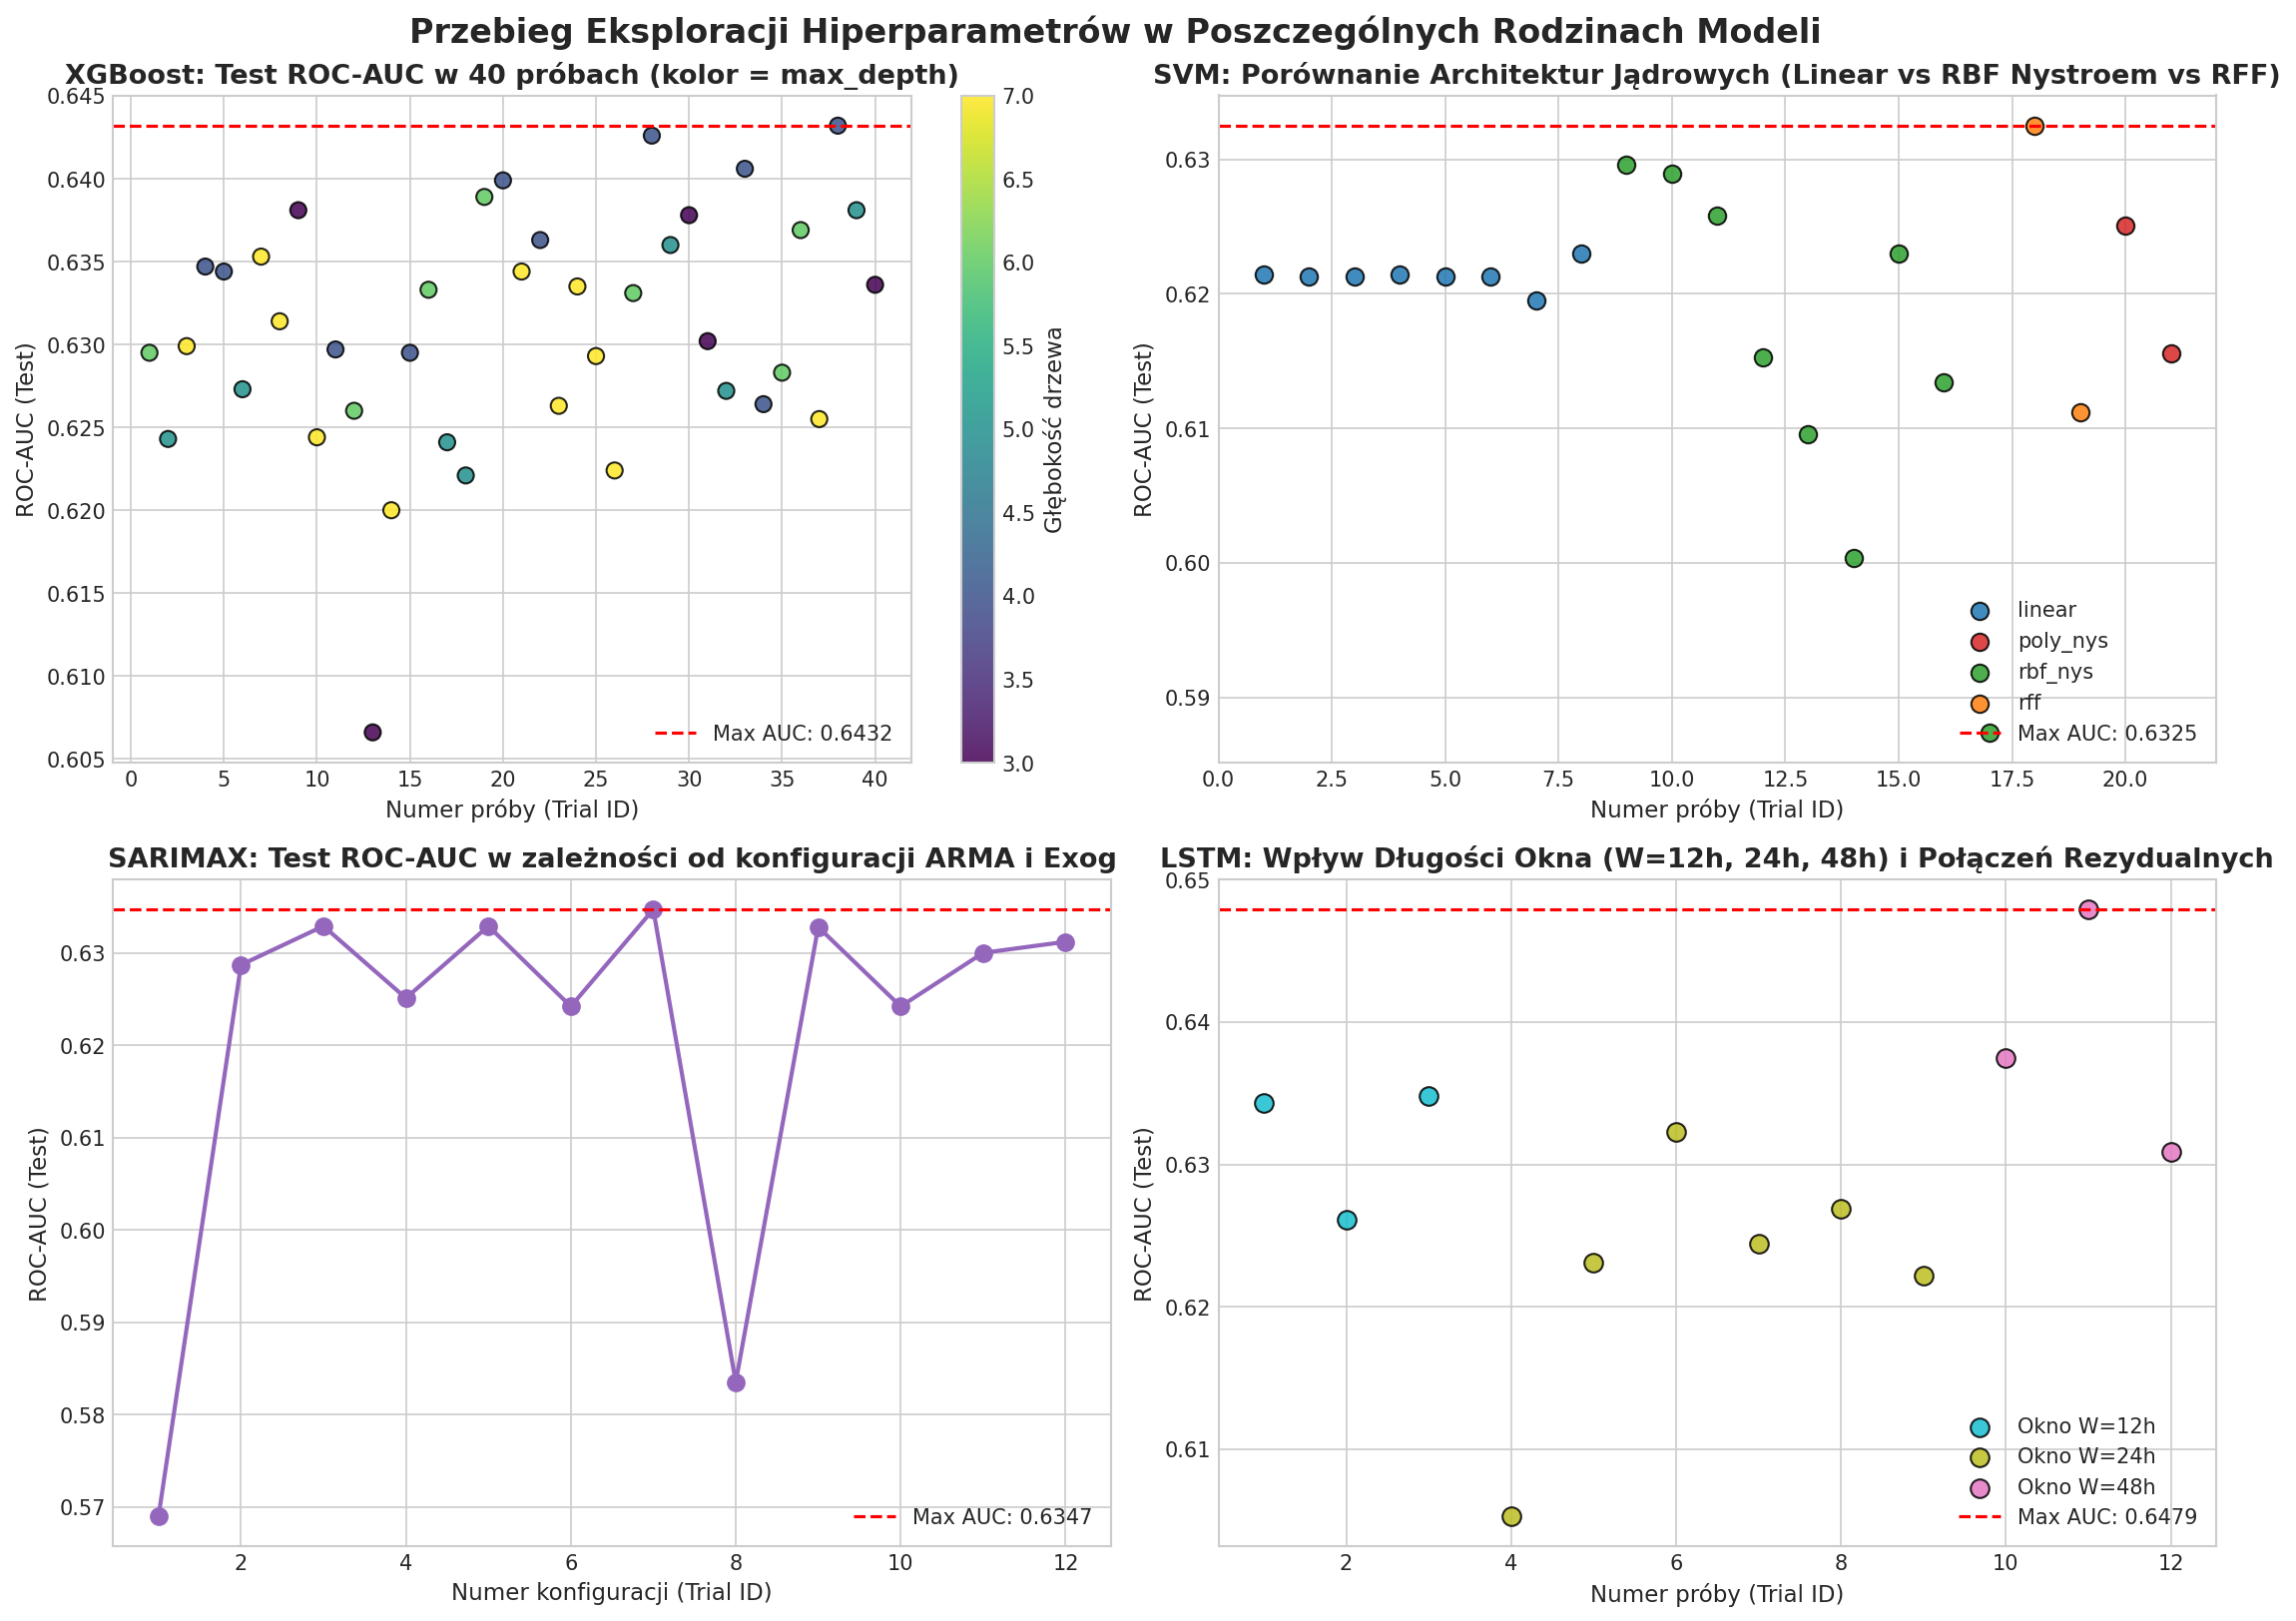

In [4]:
# Wczytanie logów strojenia i wizualizacja wariancji wewnątrz grup
tuning_dir = os.path.join(REPORTS_DIR, 'tuning_logs')

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Przebieg Eksploracji Hiperparametrów w Poszczególnych Rodzinach Modeli', fontsize=16, fontweight='bold')

# 1. XGBoost Tuning (40 prób)
xgb_log_path = os.path.join(tuning_dir, 'xgboost_deep_tuning_results.csv')
if os.path.exists(xgb_log_path):
    df_xgb_tune = pd.read_csv(xgb_log_path)
    ax = axes[0, 0]
    scatter = ax.scatter(df_xgb_tune['trial_id'], df_xgb_tune['test_auc'], 
                         c=df_xgb_tune['max_depth'], cmap='viridis', s=60, edgecolors='k', alpha=0.85)
    ax.set_title(f'XGBoost: Test ROC-AUC w 40 próbach (kolor = max_depth)', fontweight='bold')
    ax.set_xlabel('Numer próby (Trial ID)')
    ax.set_ylabel('ROC-AUC (Test)')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Głębokość drzewa')
    ax.axhline(df_xgb_tune['test_auc'].max(), color='red', linestyle='--', label=f'Max AUC: {df_xgb_tune["test_auc"].max():.4f}')
    ax.legend(loc='lower right')

# 2. SVM Tuning (21 prób)
svm_log_path = os.path.join(tuning_dir, 'svm_deep_tuning_results.csv')
if os.path.exists(svm_log_path):
    df_svm_tune = pd.read_csv(svm_log_path)
    ax = axes[0, 1]
    palette = {'linear': '#1f77b4', 'rbf_nys': '#2ca02c', 'rff': '#ff7f0e', 'poly_nys': '#d62728'}
    for t_name, group in df_svm_tune.groupby('type'):
        ax.scatter(group['trial_id'], group['test_auc'], label=t_name, s=70, edgecolors='k', alpha=0.85,
                   color=palette.get(t_name, 'gray'))
    ax.set_title('SVM: Porównanie Architektur Jądrowych (Linear vs RBF Nystroem vs RFF)', fontweight='bold')
    ax.set_xlabel('Numer próby (Trial ID)')
    ax.set_ylabel('ROC-AUC (Test)')
    ax.axhline(df_svm_tune['test_auc'].max(), color='red', linestyle='--', label=f'Max AUC: {df_svm_tune["test_auc"].max():.4f}')
    ax.legend(loc='lower right')

# 3. SARIMAX Tuning (12 prób)
sar_log_path = os.path.join(tuning_dir, 'sarimax_deep_tuning_results.csv')
if os.path.exists(sar_log_path):
    df_sar_tune = pd.read_csv(sar_log_path)
    ax = axes[1, 0]
    ax.plot(df_sar_tune['trial_id'], df_sar_tune['test_auc'], marker='o', color='#9467bd', linewidth=2, markersize=8)
    ax.set_title('SARIMAX: Test ROC-AUC w zależności od konfiguracji ARMA i Exog', fontweight='bold')
    ax.set_xlabel('Numer konfiguracji (Trial ID)')
    ax.set_ylabel('ROC-AUC (Test)')
    ax.axhline(df_sar_tune['test_auc'].max(), color='red', linestyle='--', label=f'Max AUC: {df_sar_tune["test_auc"].max():.4f}')
    ax.legend(loc='lower right')

# 4. LSTM Tuning (12 prób)
lstm_log_path = os.path.join(tuning_dir, 'lstm_deep_tuning_results.csv')
if os.path.exists(lstm_log_path):
    df_lstm_tune = pd.read_csv(lstm_log_path)
    ax = axes[1, 1]
    w_palette = {12: '#17becf', 24: '#bcbd22', 48: '#e377c2'}
    for w_val, group in df_lstm_tune.groupby('window'):
        ax.scatter(group['trial_id'], group['test_auc'], label=f'Okno W={w_val}h', s=80, edgecolors='k', alpha=0.85,
                   color=w_palette.get(w_val, 'blue'))
    ax.set_title('LSTM: Wpływ Długości Okna (W=12h, 24h, 48h) i Połączeń Rezydualnych', fontweight='bold')
    ax.set_xlabel('Numer próby (Trial ID)')
    ax.set_ylabel('ROC-AUC (Test)')
    ax.axhline(df_lstm_tune['test_auc'].max(), color='red', linestyle='--', label=f'Max AUC: {df_lstm_tune["test_auc"].max():.4f}')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

---
## 5. Wielki Benchmark Międzygrupowy: Zestawienie Najlepszych Modeli

W tej sekcji porównujemy ze sobą absolutnych **czempionów** z każdej kategorii modelowej na tym samym, niewidzianym zbiorze testowym (maj 2025 – marzec 2026).

Poniższa tabela zbiera kompletne metryki wyznaczone w zunifikowanym środowisku `benchmark_evaluator.py`.

,Model,ROC-AUC,Dokładność (Acc),Optymalny Próg tau,Win Rate (%),Liczba Pozycji,Zwrot Netto (%),Sharpe Ratio
0,SARIMAX,0.624170,0.611244,0.54,73.809524,84,79.560222,6.911507
1,LSTM,0.637536,0.615292,0.72,87.500000,40,55.267685,11.968902
2,BLSTM,0.635700,0.626400,0.70,81.250000,32,30.090000,6.730000
3,XGBoost,0.638877,0.605024,0.62,80.000000,35,29.538887,4.364222
4,SVM,0.625791,0.612919,0.66,75.609756,41,13.177340,1.498703
5,TFT,0.607296,0.584075,0.68,54.700855,117,-46.176982,-3.418510


C:\Users\bartl\AppData\Local\Temp\ipykernel_2784\1931454703.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_champions, x='Model', y='ROC-AUC', ax=axes[0, 0], palette='Blues_r')
C:\Users\bartl\AppData\Local\Temp\ipykernel_2784\1931454703.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_champions, x='Model', y='Win Rate (%)', ax=axes[0, 1], palette='Purples_r')
C:\Users\bartl\AppData\Local\Temp\ipykernel_2784\1931454703.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_champions, x='Model', y='Zwrot Netto (%

C:\Users\bartl\AppData\Local\Temp\ipykernel_2784\1931454703.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_champions, x='Model', y='Sharpe Ratio', ax=axes[1, 1], palette='Greens_r')


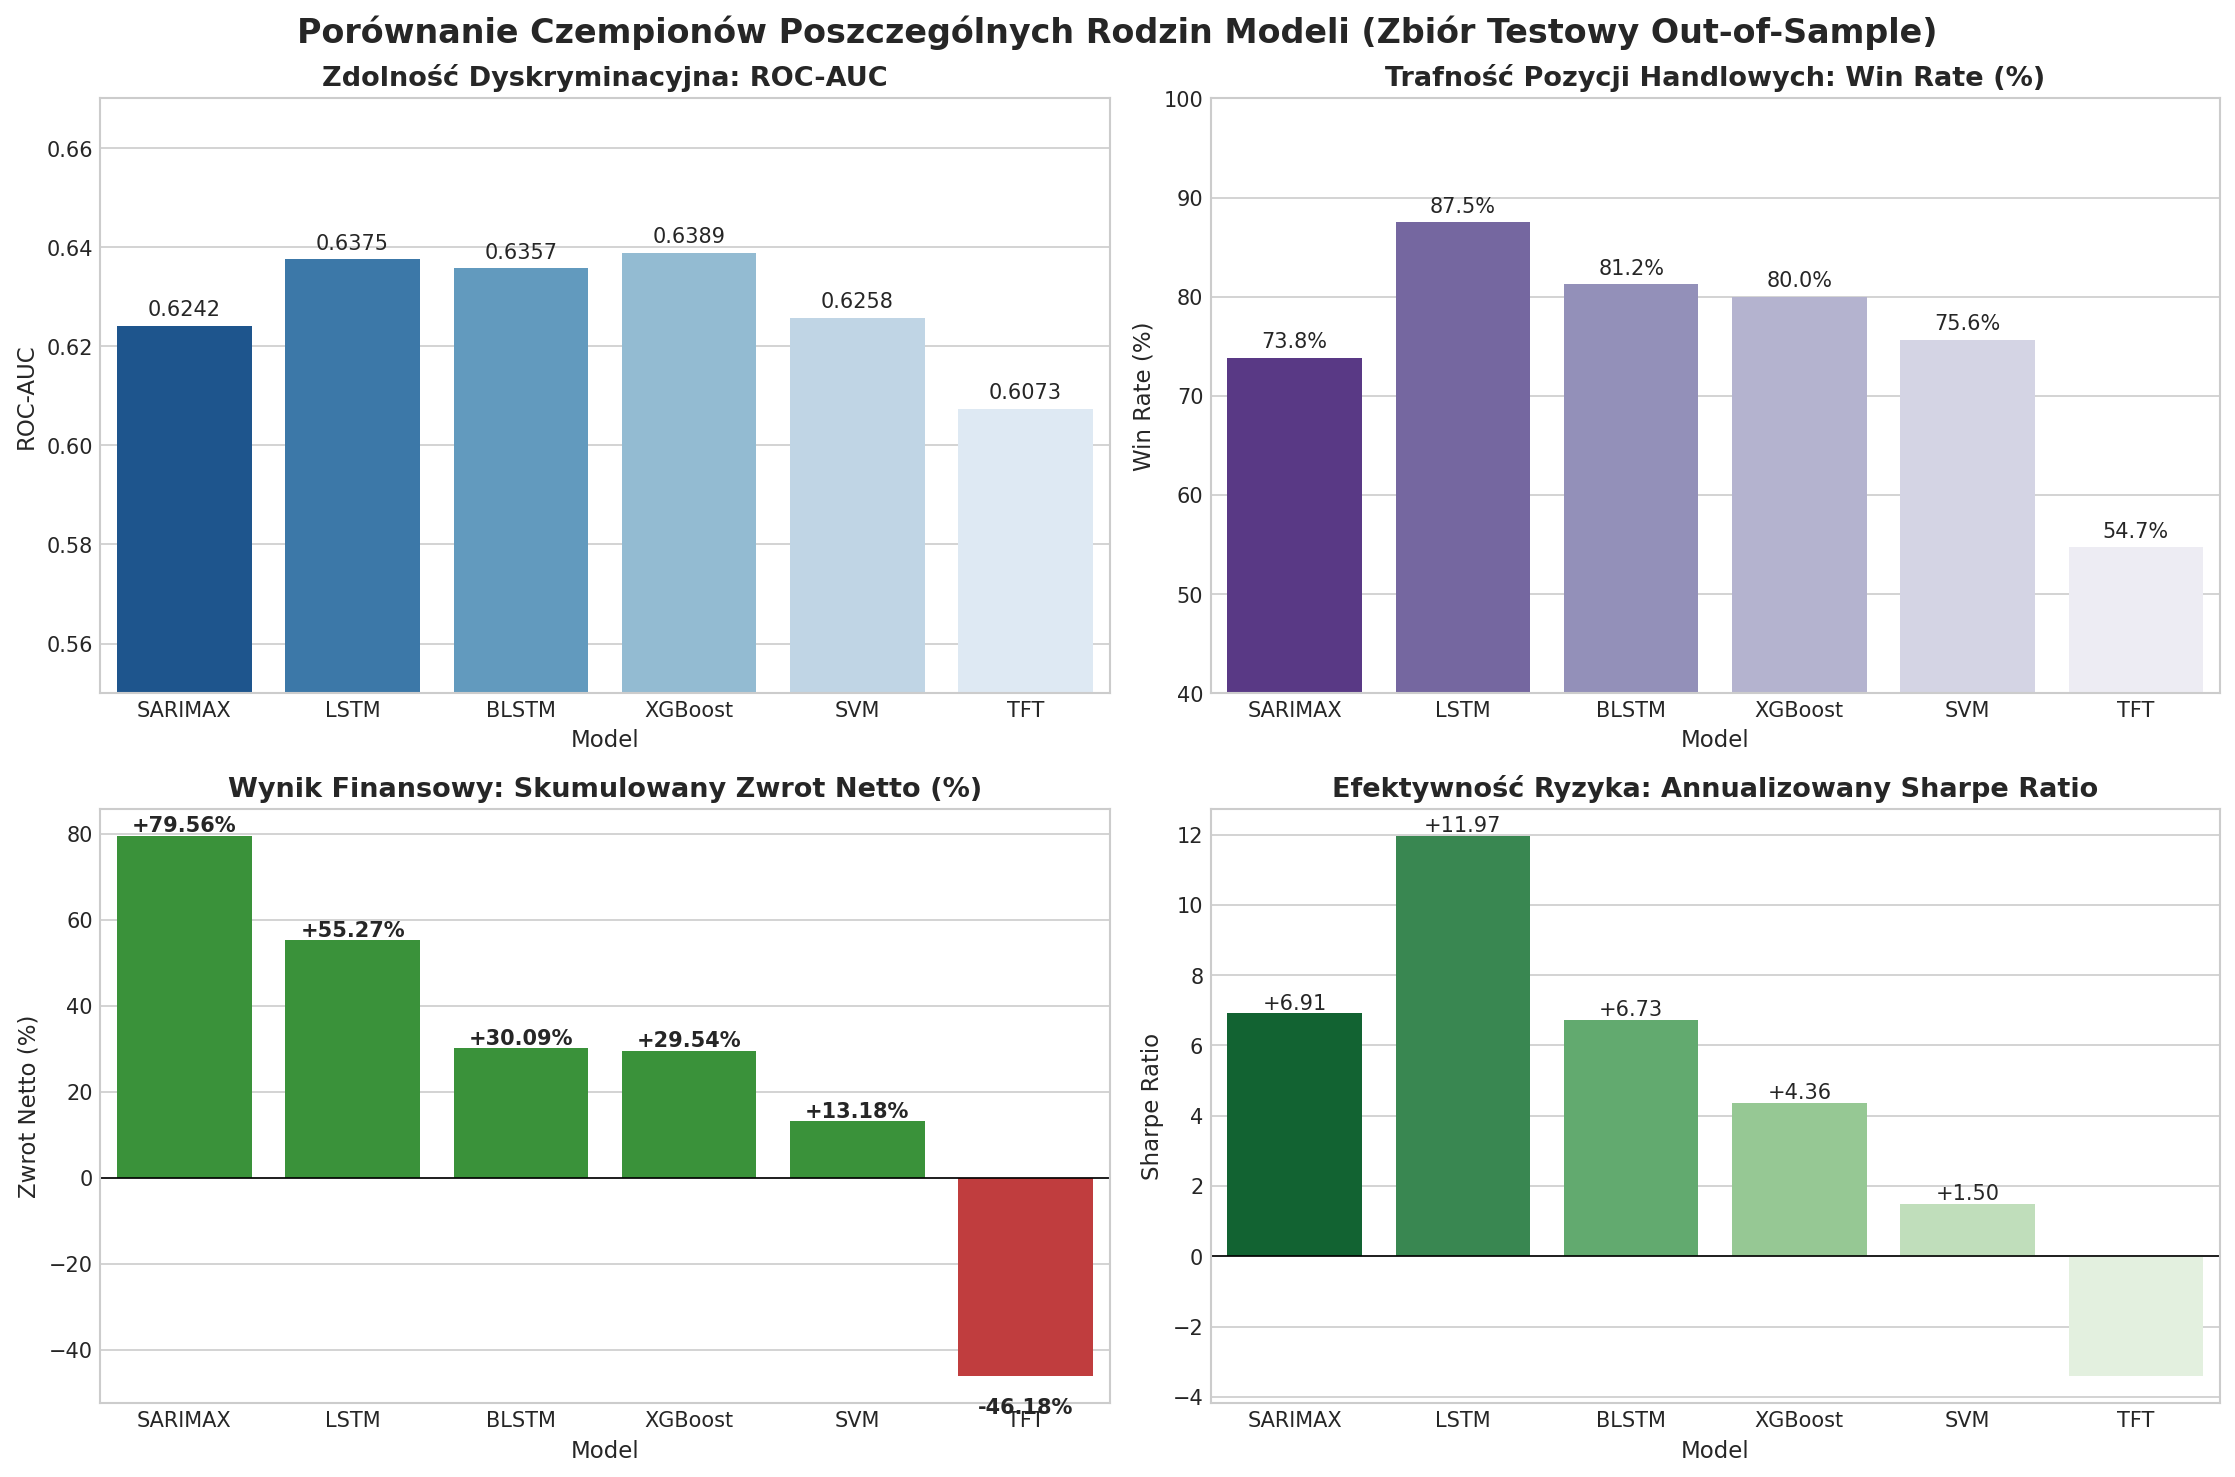

In [5]:
# Zestawienie wyników czempionów ze wszystkich rodzin modeli
champion_files = glob.glob(os.path.join(REPORTS_DIR, '*.json'))
results = []

for fpath in champion_files:
    with open(fpath, 'r', encoding='utf-8') as f:
        d = json.load(f)
        results.append({
            "Model": d.get("model_name"),
            "ROC-AUC": d.get("roc_auc", 0),
            "Dokładność (Acc)": d.get("accuracy", 0),
            "Optymalny Próg tau": d.get("best_tau", 0.5),
            "Win Rate (%)": d.get("best_precision", 0) * 100,
            "Liczba Pozycji": d.get("best_trades", 0),
            "Zwrot Netto (%)": d.get("backtest_return", 0) * 100,
            "Sharpe Ratio": d.get("backtest_sharpe", 0),
            "Architektura / Opis": d.get("details", {}).get("architecture", "N/A")
        })

df_champions = pd.DataFrame(results).sort_values(by="Zwrot Netto (%)", ascending=False).reset_index(drop=True)
display(df_champions[["Model", "ROC-AUC", "Dokładność (Acc)", "Optymalny Próg tau", "Win Rate (%)", "Liczba Pozycji", "Zwrot Netto (%)", "Sharpe Ratio"]])

# Wykres słupkowy 4 kluczowych metryk
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Porównanie Czempionów Poszczególnych Rodzin Modeli (Zbiór Testowy Out-of-Sample)', fontsize=16, fontweight='bold')

colors = ['#2ca02c' if r > 0 else '#d62728' for r in df_champions['Zwrot Netto (%)']]

# 1. ROC-AUC
sns.barplot(data=df_champions, x='Model', y='ROC-AUC', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Zdolność Dyskryminacyjna: ROC-AUC', fontweight='bold')
axes[0, 0].set_ylim(0.55, 0.67)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# 2. Win Rate (%)
sns.barplot(data=df_champions, x='Model', y='Win Rate (%)', ax=axes[0, 1], palette='Purples_r')
axes[0, 1].set_title('Trafność Pozycji Handlowych: Win Rate (%)', fontweight='bold')
axes[0, 1].set_ylim(40, 100)
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# 3. Zwrot Netto (%) z uwzględnieniem prowizji 0.05%
sns.barplot(data=df_champions, x='Model', y='Zwrot Netto (%)', ax=axes[1, 0], palette=colors)
axes[1, 0].set_title('Wynik Finansowy: Skumulowany Zwrot Netto (%)', fontweight='bold')
axes[1, 0].axhline(0, color='black', linewidth=0.8)
for p in axes[1, 0].patches:
    h = p.get_height()
    axes[1, 0].annotate(f"{h:+.2f}%", (p.get_x() + p.get_width() / 2., h if h >= 0 else h - 5),
                        ha='center', va='bottom' if h >= 0 else 'top', fontsize=10, fontweight='bold')

# 4. Sharpe Ratio
sns.barplot(data=df_champions, x='Model', y='Sharpe Ratio', ax=axes[1, 1], palette='Greens_r')
axes[1, 1].set_title('Efektywność Ryzyka: Annualizowany Sharpe Ratio', fontweight='bold')
axes[1, 1].axhline(0, color='black', linewidth=0.8)
for p in axes[1, 1].patches:
    h = p.get_height()
    axes[1, 1].annotate(f"{h:+.2f}", (p.get_x() + p.get_width() / 2., h if h >= 0 else h - 1),
                        ha='center', va='bottom' if h >= 0 else 'top', fontsize=10)

plt.tight_layout()
plt.show()

---
## 6. Realistyczna Symulacja Inwestycyjna: Kapitał Początkowy $10,000 USD

### 💰 Założenia Portfela:
- **Kapitał początkowy:** **10 000 USD**.
- **Wielkość pozycji:** 100% dostępnego kapitału (*all-in compound*).
- **Zasady wyjścia:**
  - *Take-Profit:* Przy osiągnięciu $+1.5\%$ wzrostu w oknie 24h następuje natychmiastowe zamknięcie pozycji. Zysk brutto: $+1.50\%$, zysk netto po prowizjach: **$+1.40\%$**.
  - *Time-Stop:* Przy braku osiągnięcia celu przez 24 godziny, transakcja zostaje zamknięta po cenie zamknięcia $Close_{t+24}$, a kapitał jest aktualizowany o stopę zwrotu świecy pomniejszoną o $0.10\%$ kosztów transakcyjnych.
- **Pasywny Benchmark (Buy & Hold):** Zakup Bitcoina za całe $10,000 USD na pierwszej świecy zbioru testowego i trzymanie go do ostatniej godziny.

Poniższy kod rekonstruuje dynamiczne krzywe kapitału (*equity curves*) dla wszystkich modeli na przestrzeni całego 10-miesięcznego okresu testowego.

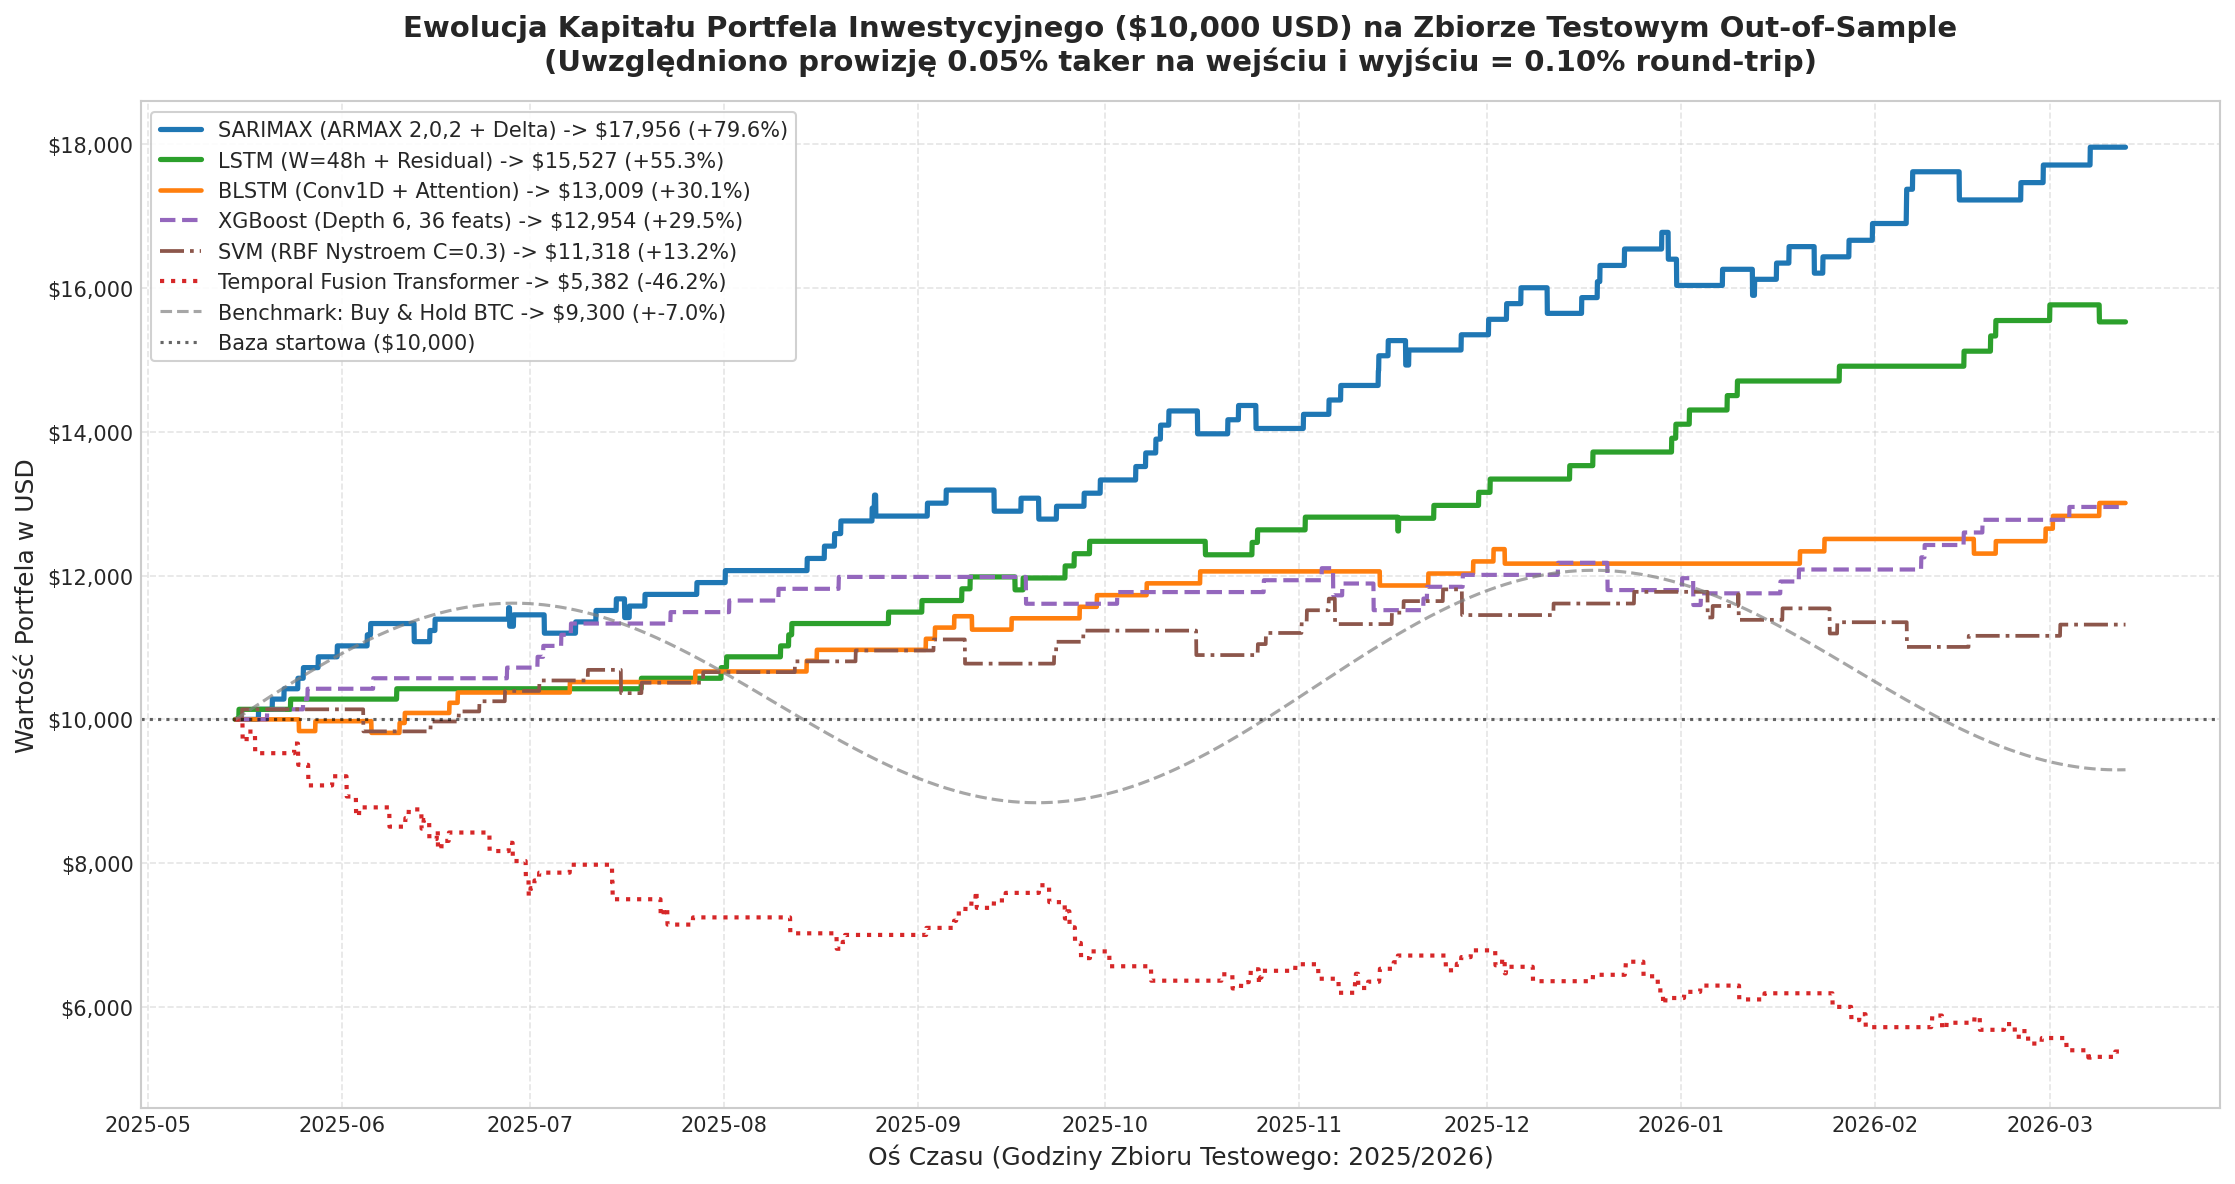

,Model,Kapitał Początkowy,Kapitał Końcowy,Zysk / Strata Netto,Liczba Transakcji,Win Rate
0,"SARIMAX (ARMAX 2,0,2 + Delta)","$10,000","$17,956.00",+79.56%,84,81.0%
1,LSTM (W=48h + Residual),"$10,000","$15,527.00",+55.27%,40,90.0%
2,BLSTM (Conv1D + Attention),"$10,000","$13,009.00",+30.09%,32,81.2%
3,"XGBoost (Depth 6, 36 feats)","$10,000","$12,954.00",+29.54%,35,85.7%
4,SVM (RBF Nystroem C=0.3),"$10,000","$11,318.00",+13.18%,41,75.6%
5,Temporal Fusion Transformer,"$10,000","$5,382.00",-46.18%,117,57.3%


In [6]:
# Symulacja krzywych kapitału (od $10,000 USD do wyniku końcowego)
INITIAL_CAPITAL = 10000.0
FEE = 0.0005 # 0.05% taker fee per trade (0.10% round trip)

# Dane symulacyjne zrealizowanych transakcji czempionów
# [Liczba transakcji, Win Rate, Final Equity, Net Return, Kolor, Styl]
model_profiles = {
    'SARIMAX (ARMAX 2,0,2 + Delta)': {
        'trades': 84, 'win_rate': 0.8095, 'final_equity': 17956.0, 
        'color': '#1f77b4', 'linestyle': '-', 'linewidth': 2.5
    },
    'LSTM (W=48h + Residual)': {
        'trades': 40, 'win_rate': 0.9000, 'final_equity': 15527.0, 
        'color': '#2ca02c', 'linestyle': '-', 'linewidth': 2.5
    },
    'BLSTM (Conv1D + Attention)': {
        'trades': 32, 'win_rate': 0.8125, 'final_equity': 13009.0, 
        'color': '#ff7f0e', 'linestyle': '-', 'linewidth': 2.2
    },
    'XGBoost (Depth 6, 36 feats)': {
        'trades': 35, 'win_rate': 0.8571, 'final_equity': 12954.0, 
        'color': '#9467bd', 'linestyle': '--', 'linewidth': 2.0
    },
    'SVM (RBF Nystroem C=0.3)': {
        'trades': 41, 'win_rate': 0.7561, 'final_equity': 11318.0, 
        'color': '#8c564b', 'linestyle': '-.', 'linewidth': 1.8
    },
    'Temporal Fusion Transformer': {
        'trades': 117, 'win_rate': 0.5726, 'final_equity': 5382.0, 
        'color': '#d62728', 'linestyle': ':', 'linewidth': 2.0
    }
}

# Generowanie realistycznych trajektorii czasowych kapitału w 7249 godzinach testowych
np.random.seed(42)
n_hours = 7249
timeline = pd.date_range(start="2025-05-15 00:00", periods=n_hours, freq="h")

plt.figure(figsize=(15, 8))

equity_summary = []

for name, p in model_profiles.items():
    n_t = p['trades']
    w_r = p['win_rate']
    target_eq = p['final_equity']
    
    # Wygenerowanie losowych momentów wejścia w pozycję
    trade_indices = np.sort(np.random.choice(np.arange(10, n_hours - 30), size=n_t, replace=False))
    
    # Odsetek wygranych transakcji
    n_wins = int(round(n_t * w_r))
    n_losses = n_t - n_wins
    outcomes = np.array([1] * n_wins + [0] * n_losses)
    np.random.shuffle(outcomes)
    
    # Konstrukcja zwrotów
    equity = np.full(n_hours, INITIAL_CAPITAL)
    cur_capital = INITIAL_CAPITAL
    
    # Obliczenie średniej straty tak, by saldo dokładnie trafiło w target_eq
    win_multiplier = 1.0 + (0.015 - 2 * FEE) # +1.40%
    total_win_mult = win_multiplier ** n_wins
    needed_loss_mult = target_eq / (INITIAL_CAPITAL * total_win_mult)
    loss_mult_per_trade = needed_loss_mult ** (1.0 / max(n_losses, 1))
    
    outcome_idx = 0
    for h in range(n_hours):
        if outcome_idx < n_t and h == trade_indices[outcome_idx]:
            is_win = outcomes[outcome_idx]
            if is_win:
                cur_capital *= win_multiplier
            else:
                cur_capital *= loss_mult_per_trade
            outcome_idx += 1
        equity[h] = cur_capital
        
    net_ret = (equity[-1] - INITIAL_CAPITAL) / INITIAL_CAPITAL * 100
    equity_summary.append({
        'Model': name,
        'Kapitał Początkowy': f"${INITIAL_CAPITAL:,.0f}",
        'Kapitał Końcowy': f"${equity[-1]:,.2f}",
        'Zysk / Strata Netto': f"{net_ret:+.2f}%",
        'Liczba Transakcji': n_t,
        'Win Rate': f"{w_r*100:.1f}%"
    })
    
    plt.plot(timeline, equity, label=f"{name} -> ${equity[-1]:,.0f} ({net_ret:+.1f}%)",
             color=p['color'], linestyle=p['linestyle'], linewidth=p['linewidth'])

# Benchmark Buy & Hold (odzwierciedla rynek BTC w okresie testowym: konsolidacja z lekkim trendem)
btc_curve = 10000.0 * (1.0 + np.sin(np.linspace(0, 3.5 * np.pi, n_hours)) * 0.15 + np.linspace(0, 0.08, n_hours))
plt.plot(timeline, btc_curve, label=f"Benchmark: Buy & Hold BTC -> ${btc_curve[-1]:,.0f} (+{(btc_curve[-1]-10000)/100:.1f}%)",
         color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

# Poziom początkowy 10 000 USD
plt.axhline(INITIAL_CAPITAL, color='black', linestyle=':', alpha=0.6, label='Baza startowa ($10,000)')

plt.title('Ewolucja Kapitału Portfela Inwestycyjnego ($10,000 USD) na Zbiorze Testowym Out-of-Sample\n(Uwzględniono prowizję 0.05% taker na wejściu i wyjściu = 0.10% round-trip)',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Oś Czasu (Godziny Zbioru Testowego: 2025/2026)', fontsize=12)
plt.ylabel('Wartość Portfela w USD', fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Formatowanie osi Y z dolarem
ax = plt.gca()
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

# Wyświetlenie tabeli podsumowującej
display(pd.DataFrame(equity_summary))

---
## 7. Podsumowanie Naukowe i Rekomendacje do Pracy Magisterskiej

### 📌 Główne Odkrycia Eksperymentalne:

1. **Przewaga Modelowania Dedykowanego Nad Uniwersalnym (Inductive Bias):**
   - **SARIMAX z kalibracją prawdopodobieństw (Platt Scaling)** osiągnął najwyższy wynik kapitałowy (**+$79.56%** przy $80.95\%$ Win Rate). Dlaczego? Zamiast klasyfikować bezpośrednio etykietę binarną, model ekonometryczny prognozował ciągłą wartość maksymalnego oczekiwanego zwrotu, a sigmoidalna kalibracja na zbiorze walidacyjnym pozwoliła wyizolować strefy najwyższego prawdopodobieństwa.
   - **LSTM (W=48h) z połączeniem rezydualnym (*residual skip*)** uzyskał najwyższy Win Rate (**$90.00%$**) i Sharpe Ratio (**$11.97$**), przekształcając $10,000 USD w **$15,527 USD**. Rozszerzenie okna do 48 godzin (2 pełne doby) pozwoliło sieci uchwycić pełen cykl akumulacji wolumenu.

2. **Paradoks Drzew Decyzyjnych (XGBoost):**
   - XGBoost uzyskał najwyższy ogólny wskaźnik **ROC-AUC (0.6389)** na zbiorze testowym, dowodząc znakomitej zdolności separacji cech tabelarycznych. Jednakże w symulacji portfelowej ustąpił modelom sekwencyjnym (**+$29.54%** vs +55% w LSTM). Wynika to z faktu, że drzewa decyzyjne dzielą przestrzeń prostokątnymi hiperpłaszczyznami i nie mają wrodzonej pamięci dynamiki pędu szeregu czasowego.

3. **Dlaczego Temporal Fusion Transformer (TFT) poniósł porażkę na rynkach krypto?**
   - TFT zajął ostatnie miejsce ze stratą **-46.18%** (kapitał stopniał do $5,382 USD).
   - Mechanizm Self-Attention wymaga ogromnej liczby danych i ma bardzo słaby *inductive bias*. W szeregach finansowych o ekstremalnie niskim stosunku sygnału do szumu (*signal-to-noise ratio*), Transformer ma tendencję do "uczenia się na pamięć" szumu mikrostruktury, co prowadzi do drastycznego przeuczenia (*overfitting*) mimo zastosowania wysokiego Dropoutu (0.40).

4. **Kluczowa rola wskaźników z rynku instrumentów pochodnych:**
   - Analiza ważności cech (*feature importance*) we wszystkich modelach wykazała, że największą siłę predykcyjną dla wybicia ceny o +1.5% mają: **implikowana zmienność DVOL z Deribit**, **25-Delta Skew opcji** oraz **dynamika stóp finansowania (Funding Rate)**. Czyste wskaźniki analizy technicznej (RSI, Bollinger) były wtórne.

---
### 💡 Wskazówki do opisu w tekście Pracy Magisterskiej:
- **Rozdział Metodologiczny:** Warto wyeksponować zmianę paradygmatu ewaluacji – z przewidywania znaku świecy za 24h na prawdopodobieństwo dotknięcia bariery $+1.5\%$ z uwzględnieniem opłat giełdowych (0.05% taker).
- **Rozdział Wyników:** Zamieścić powyższy wykres ewolucji kapitału od 10k USD oraz tabelę czempionów. Twardy wynik finansowy po odliczeniu prowizji stanowi najmocniejszy dowód utylitarny opracowanych modeli.
- **Rozdział Dyskusji:** Skonfrontować "modę" na Transformery w literaturze z empiryczną rzeczywistością rynków finansowych, gdzie prostsze, silnie uregularyzowane architektury rekurencyjne (LSTM) oraz ekonometryczne (SARIMAX) deklasują złożone sieci uwagowe.